In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

folder_path = "/content/drive/MyDrive/Data_Drift_project"

print(os.listdir(folder_path))

['yellow_tripdata_2020-04.parquet', 'yellow_tripdata_2023-01.parquet', 'yellow_tripdata_2019-01.parquet']


In [6]:
import pandas as pd
import os

folder_path = "/content/drive/MyDrive/Data_Drift_project"

files = {
    "2019_Jan (T0)": os.path.join(folder_path, "yellow_tripdata_2019-01.parquet"),
    "2020_Apr (T1)": os.path.join(folder_path, "yellow_tripdata_2020-04.parquet"),
    "2023_Apr (T2)": os.path.join(folder_path, "yellow_tripdata_2023-01.parquet")
}

raw_cols = [
    'tpep_pickup_datetime', 'tpep_dropoff_datetime',
    'passenger_count', 'trip_distance', 'ratecodeid',
    'pulocationid', 'dolocationid', 'payment_type',
    'fare_amount', 'tip_amount', 'total_amount'
]

audit_results = []

for name, path in files.items():
    print(f"Auditing {name}...")
    df = pd.read_parquet(path)
    df.columns = df.columns.str.lower()

    # Check karein ke saare required columns maujood hain ya nahi
    missing_cols = [c for c in raw_cols if c not in df.columns]
    if missing_cols:
        print(f"  [WARNING] Missing columns in {name}: {missing_cols}")
        continue

    df = df[raw_cols]
    total_rows = len(df)

    # 1. Missing (Null) values check
    null_rows = df.isnull().any(axis=1).sum()

    # 2. Exact Duplicate rows check
    duplicate_rows = df.duplicated().sum()

    # 3. Date/Time anomalies (Dropoff pickup se pehle ya barabar ho, ya year ghalat ho)
    pickup = pd.to_datetime(df['tpep_pickup_datetime'])
    dropoff = pd.to_datetime(df['tpep_dropoff_datetime'])
    bad_time = (dropoff <= pickup).sum()

    expected_year = int(name.split("_")[0])
    wrong_year = (pickup.dt.year != expected_year).sum()

    # 4. Impossible / Outlier values
    bad_distance = ((df['trip_distance'] <= 0) | (df['trip_distance'] > 100)).sum()
    bad_fare = ((df['fare_amount'] <= 0) | (df['fare_amount'] > 300)).sum()
    bad_passengers = ((df['passenger_count'] <= 0) | (df['passenger_count'] > 6)).sum()

    audit_results.append({
        "Dataset": name,
        "Total Rows": total_rows,
        "Rows with Nulls": null_rows,
        "Duplicate Rows": duplicate_rows,
        "Dropoff <= Pickup": bad_time,
        "Wrong Year Records": wrong_year,
        "Invalid Distance (<=0 or >100)": bad_distance,
        "Invalid Fare (<=0 or >300)": bad_fare,
        "Invalid Passengers (<=0 or >6)": bad_passengers
    })

# Audit Report ko clean table mein print karein
audit_df = pd.DataFrame(audit_results)
print("\n=== DATA QUALITY AUDIT REPORT ===")
display(audit_df)

# Column-wise missing values detail bhi check karein
print("\n=== COLUMN-WISE MISSING VALUES (NULLS) ===")
for name, path in files.items():
    df = pd.read_parquet(path)
    df.columns = df.columns.str.lower()
    nulls = df[raw_cols].isnull().sum()
    nulls = nulls[nulls > 0]
    print(f"\n{name}:")
    print(nulls if len(nulls) > 0 else "  No missing values!")

Auditing 2019_Jan (T0)...
Auditing 2020_Apr (T1)...
Auditing 2023_Apr (T2)...

=== DATA QUALITY AUDIT REPORT ===


,Dataset,Total Rows,Rows with Nulls,Duplicate Rows,Dropoff <= Pickup,Wrong Year Records,Invalid Distance (<=0 or >100),Invalid Fare (<=0 or >300),Invalid Passengers (<=0 or >6)
0,2019_Jan (T0),7696617,28672,0,6557,443,55121,9938,117438
1,2020_Apr (T1),238073,19580,0,315,1,6237,1476,6583
2,2023_Apr (T2),3066766,71743,0,1121,38,45950,26372,51184



=== COLUMN-WISE MISSING VALUES (NULLS) ===

2019_Jan (T0):
passenger_count    28672
ratecodeid         28672
dtype: int64

2020_Apr (T1):
passenger_count    19580
ratecodeid         19580
dtype: int64

2023_Apr (T2):
passenger_count    71743
ratecodeid         71743
dtype: int64


In [8]:
import pandas as pd
import os

folder_path = "/content/drive/MyDrive/Data_Drift_project"

files = {
    "T0_2019_01": (os.path.join(folder_path, "yellow_tripdata_2019-01.parquet"), 2019),
    "T1_2020_04": (os.path.join(folder_path, "yellow_tripdata_2020-04.parquet"), 2020),
    "T2_2023_01": (os.path.join(folder_path, "yellow_tripdata_2023-01.parquet"), 2023)
}

raw_cols = [
    'tpep_pickup_datetime', 'tpep_dropoff_datetime',
    'passenger_count', 'trip_distance', 'ratecodeid',
    'pulocationid', 'dolocationid', 'payment_type',
    'fare_amount', 'tip_amount', 'total_amount'
]

def targeted_clean(file_path, expected_year, batch_name, sample_size=50000):
    df = pd.read_parquet(file_path)
    df.columns = df.columns.str.lower()
    df = df[raw_cols].copy()

    before_count = len(df)

    # 1. Remove Nulls (passenger_count & ratecodeid)
    df = df.dropna()

    # 2. Remove Wrong Year & Invalid Timestamps
    pickup = pd.to_datetime(df['tpep_pickup_datetime'])
    dropoff = pd.to_datetime(df['tpep_dropoff_datetime'])
    df = df[(pickup.dt.year == expected_year) & (dropoff > pickup)]

    # 3. Remove Invalid Distance, Fare, and Passenger Outliers
    df = df[
        (df['trip_distance'] > 0.1) & (df['trip_distance'] < 100) &
        (df['fare_amount'] > 2.5) & (df['fare_amount'] < 300) &
        (df['passenger_count'] >= 1) & (df['passenger_count'] <= 6)
    ]

    after_count = len(df)
    print(f"{batch_name}: Raw = {before_count:,} -> Clean = {after_count:,} (Removed {before_count - after_count:,} bad rows)")

    # 4. Sample 50,000 clean rows
    df_sampled = df.sample(n=sample_size, random_state=42).copy()
    df_sampled['batch'] = batch_name
    return df_sampled

# Run targeted cleaning
df_2019 = targeted_clean(*files["T0_2019_01"], "T0_2019_01")
df_2020 = targeted_clean(*files["T1_2020_04"], "T1_2020_04")
df_2023 = targeted_clean(*files["T2_2023_01"], "T2_2023_01")

# Save clean CSV files
df_2019.to_csv(os.path.join(folder_path, "clean_2019.csv"), index=False)
df_2020.to_csv(os.path.join(folder_path, "clean_2020.csv"), index=False)
df_2023.to_csv(os.path.join(folder_path, "clean_2023.csv"), index=False)

print("\nAll 3 clean datasets saved successfully! Shapes:", df_2019.shape, df_2020.shape, df_2023.shape)

T0_2019_01: Raw = 7,696,617 -> Clean = 7,463,806 (Removed 232,811 bad rows)
T1_2020_04: Raw = 238,073 -> Clean = 204,089 (Removed 33,984 bad rows)
T2_2023_01: Raw = 3,066,766 -> Clean = 2,876,007 (Removed 190,759 bad rows)

All 3 clean datasets saved successfully! Shapes: (50000, 12) (50000, 12) (50000, 12)


In [9]:
import pandas as pd
import os

folder_path = "/content/drive/MyDrive/Data_Drift_project"
clean_files = ["clean_2019.csv", "clean_2020.csv", "clean_2023.csv"]

for fname in clean_files:
    df = pd.read_csv(os.path.join(folder_path, fname))
    print(f"==========================================")
    print(f"VERIFICATION REPORT: {fname} (Rows: {len(df)})")
    print(f"==========================================")

    # 1. Nulls & Duplicates Check
    print(f"Total Nulls: {df.isnull().sum().sum()} | Exact Duplicates: {df.duplicated().sum()}")

    # 2. Numeric Min / Max / Mean Check
    num_cols = ['passenger_count', 'trip_distance', 'fare_amount', 'tip_amount', 'total_amount']
    display(df[num_cols].describe().loc[['min', 'mean', 'max']].round(2))

    # 3. Categorical Values Check (RatecodeID & Payment Type)
    print("Unique RatecodeIDs:", sorted(df['ratecodeid'].unique().tolist()))
    print("Unique Payment Types:", sorted(df['payment_type'].unique().tolist()))
    print("Invalid Ratecode (99) count:", (df['ratecodeid'] == 99).sum())
    print("\n")

VERIFICATION REPORT: clean_2019.csv (Rows: 50000)
Total Nulls: 0 | Exact Duplicates: 0


,passenger_count,trip_distance,fare_amount,tip_amount,total_amount
min,1.00,0.11,3.00,0.00,3.80
mean,1.59,2.83,12.18,1.83,15.47
max,6.00,73.45,208.00,52.08,260.38


Unique RatecodeIDs: [1.0, 2.0, 3.0, 4.0, 5.0]
Unique Payment Types: [1, 2, 3, 4]
Invalid Ratecode (99) count: 0


VERIFICATION REPORT: clean_2020.csv (Rows: 50000)
Total Nulls: 0 | Exact Duplicates: 0


,passenger_count,trip_distance,fare_amount,tip_amount,total_amount
min,1.00,0.11,3.00,0.00,3.80
mean,1.35,2.69,10.52,1.54,15.38
max,6.00,73.19,281.50,99.00,308.42


Unique RatecodeIDs: [1.0, 2.0, 3.0, 4.0, 5.0, 99.0]
Unique Payment Types: [1, 2, 3, 4]
Invalid Ratecode (99) count: 2


VERIFICATION REPORT: clean_2023.csv (Rows: 50000)
Total Nulls: 0 | Exact Duplicates: 0


,passenger_count,trip_distance,fare_amount,tip_amount,total_amount
min,1.00,0.11,3.00,0.00,5.20
mean,1.39,3.42,18.47,3.39,27.26
max,6.00,49.32,255.00,85.00,270.25


Unique RatecodeIDs: [1.0, 2.0, 3.0, 4.0, 5.0, 99.0]
Unique Payment Types: [1, 2, 3, 4]
Invalid Ratecode (99) count: 178




Step 1B: Feature Engineering + Final Polish


In [10]:
def prepare_features(df):
    df = df.copy()

    # 1. Invalid RatecodeID (99) remove karna
    df = df[df['ratecodeid'] != 99.0]

    # 2. Timestamps se time-based features nikalna
    pickup = pd.to_datetime(df['tpep_pickup_datetime'])
    dropoff = pd.to_datetime(df['tpep_dropoff_datetime'])

    df['trip_duration_min'] = (dropoff - pickup).dt.total_seconds() / 60.0
    df['pickup_hour'] = pickup.dt.hour
    df['day_of_week'] = pickup.dt.dayofweek
    df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

    # 3. Impossible trip durations hatana (1 min se kam ya 3 ghante se zyada)
    df = df[(df['trip_duration_min'] >= 1.0) & (df['trip_duration_min'] <= 180.0)]

    # 4. Raw timestamps aur Data Leakage columns (tip_amount, total_amount) hatana
    df = df.drop(columns=['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'tip_amount', 'total_amount'])

    return df

# Teeno DataFrames ko model-ready banayein
df_2019_ready = prepare_features(df_2019)
df_2020_ready = prepare_features(df_2020)
df_2023_ready = prepare_features(df_2023)

print("Model-Ready Shapes:")
print("2019:", df_2019_ready.shape)
print("2020:", df_2020_ready.shape)
print("2023:", df_2023_ready.shape)
display(df_2019_ready.head(3))

Model-Ready Shapes:
2019: (49818, 12)
2020: (49736, 12)
2023: (49716, 12)


,passenger_count,trip_distance,ratecodeid,pulocationid,dolocationid,payment_type,fare_amount,batch,trip_duration_min,pickup_hour,day_of_week,is_weekend
4480694,1.0,1.3,1.0,79,249,1,7.5,T0_2019_01,8.766667,11,5,1
1018706,1.0,0.8,1.0,161,162,2,5.5,T0_2019_01,5.716667,18,5,1
6145141,1.0,0.7,1.0,75,41,2,5.0,T0_2019_01,4.150000,2,5,1


Step 2 (Baseline Model Training on 2019) and Step 3 (Model Degradation Test on 2020 & 2023)

=== MODEL RELIABILITY & DEGRADATION REPORT ===


,Batch / Era,RMSE ($),MAE ($),R2 Score
0,T0: 2019 Jan (Baseline Test),1.723,0.367,0.9750
1,T1: 2020 Apr (COVID Lockdown),1.882,0.401,0.9578
2,T2: 2023 jan (Post-COVID Inflation),6.862,4.673,0.8270


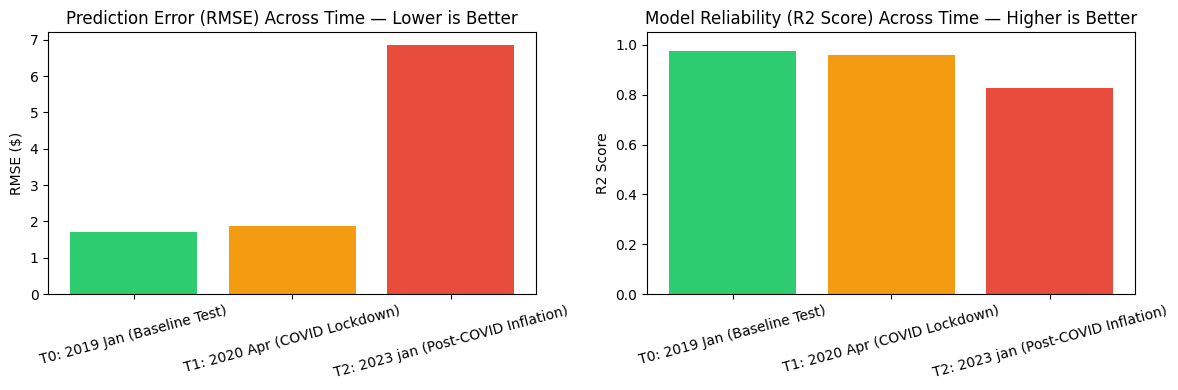

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from xgboost import XGBRegressor

# 1. Input Features (X) aur Target (y) define karein
feature_cols = [
    'passenger_count', 'trip_distance', 'ratecodeid',
    'pulocationid', 'dolocationid', 'payment_type',
    'trip_duration_min', 'pickup_hour', 'day_of_week', 'is_weekend'
]
target_col = 'fare_amount'

# 2. Step 2: 2019 Data ko 80% Train aur 20% Baseline Test mein split karein
X_2019 = df_2019_ready[feature_cols]
y_2019 = df_2019_ready[target_col]

X_train, X_test_2019, y_train, y_test_2019 = train_test_split(
    X_2019, y_2019, test_size=0.2, random_state=42
)

# Baseline XGBoost Model train karein (Sirf 2019 data par)
baseline_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)
baseline_model.fit(X_train, y_train)

def evaluate_batch(model, X, y, batch_label):
    preds = model.predict(X)
    rmse = np.sqrt(mean_squared_error(y, preds))
    mae = mean_absolute_error(y, preds)
    r2 = r2_score(y, preds)
    return {
        "Batch / Era": batch_label,
        "RMSE ($)": round(rmse, 3),
        "MAE ($)": round(mae, 3),
        "R2 Score": round(r2, 4)
    }

results = [
    evaluate_batch(baseline_model, X_test_2019, y_test_2019, "T0: 2019 Jan (Baseline Test)"),
    evaluate_batch(baseline_model, df_2020_ready[feature_cols], df_2020_ready[target_col], "T1: 2020 Apr (COVID Lockdown)"),
    evaluate_batch(baseline_model, df_2023_ready[feature_cols], df_2023_ready[target_col], "T2: 2023 jan (Post-COVID Inflation)")
]

results_df = pd.DataFrame(results)
print("=== MODEL RELIABILITY & DEGRADATION REPORT ===")
display(results_df)

# 4. Visual Degradation Plot (RMSE aur R2 Score)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(results_df["Batch / Era"], results_df["RMSE ($)"], color=['#2ecc71', '#f39c12', '#e74c3c'])
axes[0].set_title("Prediction Error (RMSE) Across Time — Lower is Better")
axes[0].set_ylabel("RMSE ($)")
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(results_df["Batch / Era"], results_df["R2 Score"], color=['#2ecc71', '#f39c12', '#e74c3c'])
axes[1].set_title("Model Reliability (R2 Score) Across Time — Higher is Better")
axes[1].set_ylabel("R2 Score")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

Multi-Model Reliability Comparison

Training Random Forest & Ridge Regression on 2019 data...

=== MULTI-MODEL RELIABILITY COMPARISON ===


RMSE ($)                            \
Model                    Random Forest (Bagging) Ridge Regression (Linear)   
Batch                                                                        
T0: 2019 Jan (Baseline)                    1.656                     2.551   
T1: 2020 Apr (Lockdown)                    1.645                     1.661   
T2: 2023 Jan (Inflation)                   6.823                     7.197   

                                                                R2 Score  \
Model                    XGBoost (Tree Boosting) Random Forest (Bagging)   
Batch                                                                      
T0: 2019 Jan (Baseline)                    1.723                  0.9769   
T1: 2020 Apr (Lockdown)                    1.882                  0.9677   
T2: 2023 Jan (Inflation)                   6.862                  0.8289   

                                                                            
Model                    Ridge Regression (Linear) XGBoost (Tree Boosting)  
Batch                                                                       
T0: 2019 Jan (Baseline)                     0.9452                  0.9750  
T1: 2020 Apr (Lockdown)                     0.9671                  0.9578  
T2: 2023 Jan (Inflation)                    0.8097                  0.8270

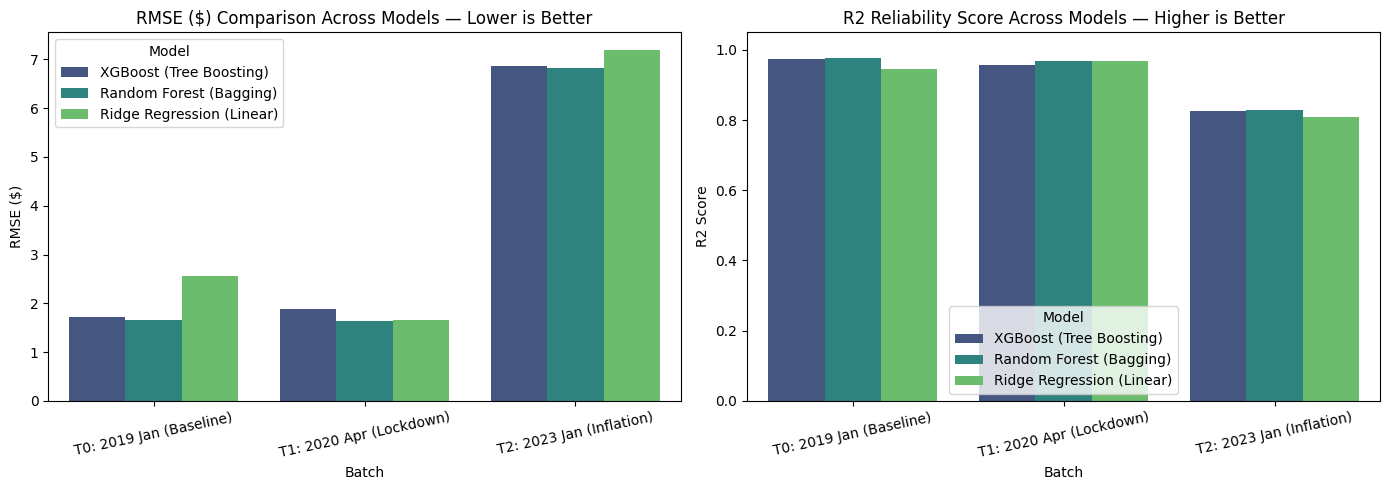

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models = {
    "XGBoost (Tree Boosting)": baseline_model,
    "Random Forest (Bagging)": RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1),
    "Ridge Regression (Linear)": make_pipeline(StandardScaler(), Ridge(alpha=1.0))
}
print("Training Random Forest & Ridge Regression on 2019 data...")
models["Random Forest (Bagging)"].fit(X_train, y_train)
models["Ridge Regression (Linear)"].fit(X_train, y_train)


batches = [
    ("T0: 2019 Jan (Baseline)", X_test_2019, y_test_2019),
    ("T1: 2020 Apr (Lockdown)", df_2020_ready[feature_cols], df_2020_ready[target_col]),
    ("T2: 2023 Jan (Inflation)", df_2023_ready[feature_cols], df_2023_ready[target_col])
]

multi_results = []
for model_name, model in models.items():
    for batch_name, X_b, y_b in batches:
        preds = model.predict(X_b)
        rmse = np.sqrt(mean_squared_error(y_b, preds))
        mae = mean_absolute_error(y_b, preds)
        r2 = r2_score(y_b, preds)
        multi_results.append({
            "Model": model_name,
            "Batch": batch_name,
            "RMSE ($)": round(rmse, 3),
            "MAE ($)": round(mae, 3),
            "R2 Score": round(r2, 4)
        })

multi_df = pd.DataFrame(multi_results)
print("\n=== MULTI-MODEL RELIABILITY COMPARISON ===")
display(multi_df.pivot(index="Batch", columns="Model", values=["RMSE ($)", "R2 Score"]))

# 3. Grouped Comparison Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=multi_df, x="Batch", y="RMSE ($)", hue="Model", ax=axes[0], palette="viridis")
axes[0].set_title("RMSE ($) Comparison Across Models — Lower is Better")
axes[0].tick_params(axis='x', rotation=12)

sns.barplot(data=multi_df, x="Batch", y="R2 Score", hue="Model", ax=axes[1], palette="viridis")
axes[1].set_title("R2 Reliability Score Across Models — Higher is Better")
axes[1].set_ylim(0, 1.05)
axes[1].tick_params(axis='x', rotation=12)

plt.tight_layout()
plt.show()

Statistical Drift Detection (PSI & KS-Test)

=== STATISTICAL DRIFT DETECTION REPORT (PSI & KS-TEST) ===


,Feature / Target,2020 PSI,2020 Status,2023 PSI,2023 Status,2023 KS-Stat
0,trip_distance,0.0212,No Drift (Safe),0.0397,No Drift (Safe),0.0835
1,trip_duration_min,0.2510,SEVERE DRIFT (Alert!),0.0316,No Drift (Safe),0.0732
2,passenger_count,0.0756,No Drift (Safe),0.0274,No Drift (Safe),0.0501
3,pickup_hour,0.1591,Moderate Drift (Warning),0.0171,No Drift (Safe),0.0487
4,fare_amount,0.0476,No Drift (Safe),0.8162,SEVERE DRIFT (Alert!),0.2943


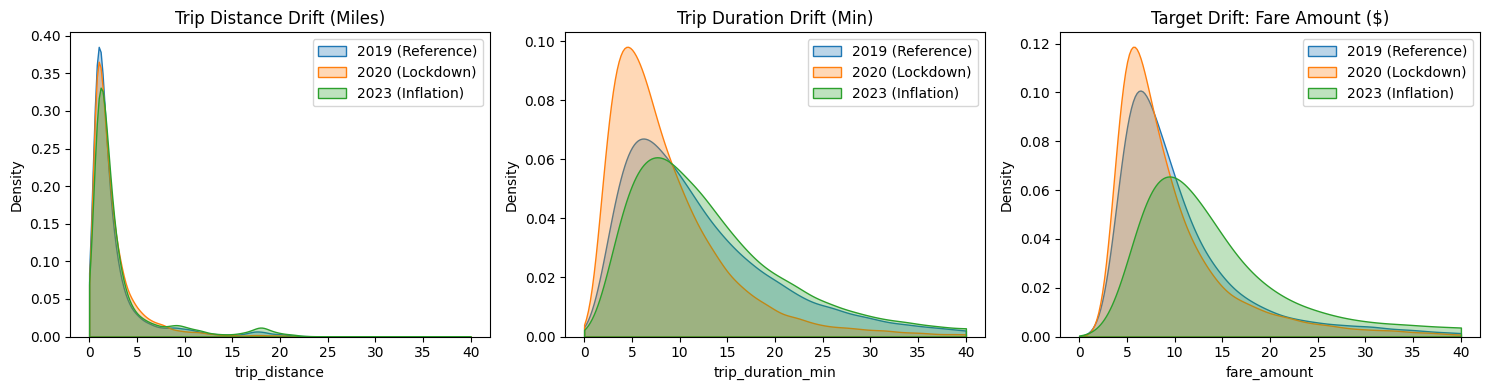

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp

# 1. Population Stability Index (PSI) Function
def calculate_psi(expected, actual, buckets=10):
    breakpoints = np.percentile(expected, np.linspace(0, 100, buckets + 1))
    breakpoints = np.unique(breakpoints)  # Duplicate bin edges hatana

    expected_counts = np.histogram(expected, bins=breakpoints)[0] / len(expected)
    actual_counts = np.histogram(actual, bins=breakpoints)[0] / len(actual)

    # Zero division se bachne ke liye small epsilon add karna
    expected_counts = np.where(expected_counts == 0, 0.0001, expected_counts)
    actual_counts = np.where(actual_counts == 0, 0.0001, actual_counts)

    psi_val = np.sum((actual_counts - expected_counts) * np.log(actual_counts / expected_counts))
    return round(psi_val, 4)

def drift_status(psi):
    if psi < 0.1:
        return "No Drift (Safe)"
    elif psi < 0.2:
        return "Moderate Drift (Warning)"
    else:
        return "SEVERE DRIFT (Alert!)"

# 2. Features + Target par Drift Audit (2019 vs 2020 & 2023)
check_cols = ['trip_distance', 'trip_duration_min', 'passenger_count', 'pickup_hour', 'fare_amount']
drift_report = []

for col in check_cols:
    ref = df_2019_ready[col]

    # 2020 comparison
    psi_2020 = calculate_psi(ref, df_2020_ready[col])
    ks_2020, p_2020 = ks_2samp(ref, df_2020_ready[col])

    # 2023 comparison
    psi_2023 = calculate_psi(ref, df_2023_ready[col])
    ks_2023, p_2023 = ks_2samp(ref, df_2023_ready[col])

    drift_report.append({
        "Feature / Target": col,
        "2020 PSI": psi_2020,
        "2020 Status": drift_status(psi_2020),
        "2023 PSI": psi_2023,
        "2023 Status": drift_status(psi_2023),
        "2023 KS-Stat": round(ks_2023, 4)
    })

drift_df = pd.DataFrame(drift_report)
print("=== STATISTICAL DRIFT DETECTION REPORT (PSI & KS-TEST) ===")
display(drift_df)

# 3. KDE Distribution Shift Plots (2019 vs 2020 vs 2023)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_cols = ['trip_distance', 'trip_duration_min', 'fare_amount']
titles = ['Trip Distance Drift (Miles)', 'Trip Duration Drift (Min)', 'Target Drift: Fare Amount ($)']

for i, col in enumerate(plot_cols):
    sns.kdeplot(df_2019_ready[col], ax=axes[i], label='2019 (Reference)', fill=True, alpha=0.3, clip=(0, 40))
    sns.kdeplot(df_2020_ready[col], ax=axes[i], label='2020 (Lockdown)', fill=True, alpha=0.3, clip=(0, 40))
    sns.kdeplot(df_2023_ready[col], ax=axes[i], label='2023 (Inflation)', fill=True, alpha=0.3, clip=(0, 40))
    axes[i].set_title(titles[i])
    axes[i].legend()

plt.tight_layout()
plt.show()

Reliability Restoration & Automated Drift-Triggered Retraining

=== FINAL RELIABILITY RESTORATION & RETRAINING REPORT ===


,Time Window,Static RMSE ($),Periodic RMSE ($),Adaptive RMSE ($),Static R2,Adaptive R2,Adaptive System Decision
0,T0: 2019 Jan (Ref),1.723,1.723,1.723,0.9750,0.9750,No Retrain Needed (Model Reliable)
1,T1: 2020 Apr (Batch 1),1.869,1.869,1.869,0.9562,0.9562,No Retrain Needed (Model Reliable)
2,T2: 2020 Apr (Batch 2),1.895,1.954,1.895,0.9592,0.9592,No Retrain Needed (Model Reliable)
3,T3: 2023 Jan (Batch 1),6.953,6.624,6.953,0.8247,0.8247,DRIFT ALERT! Model Retrained & Adapted
4,T4: 2023 Jan (Batch 2),6.769,2.118,2.118,0.8294,0.9833,No Retrain Needed (Model Reliable)


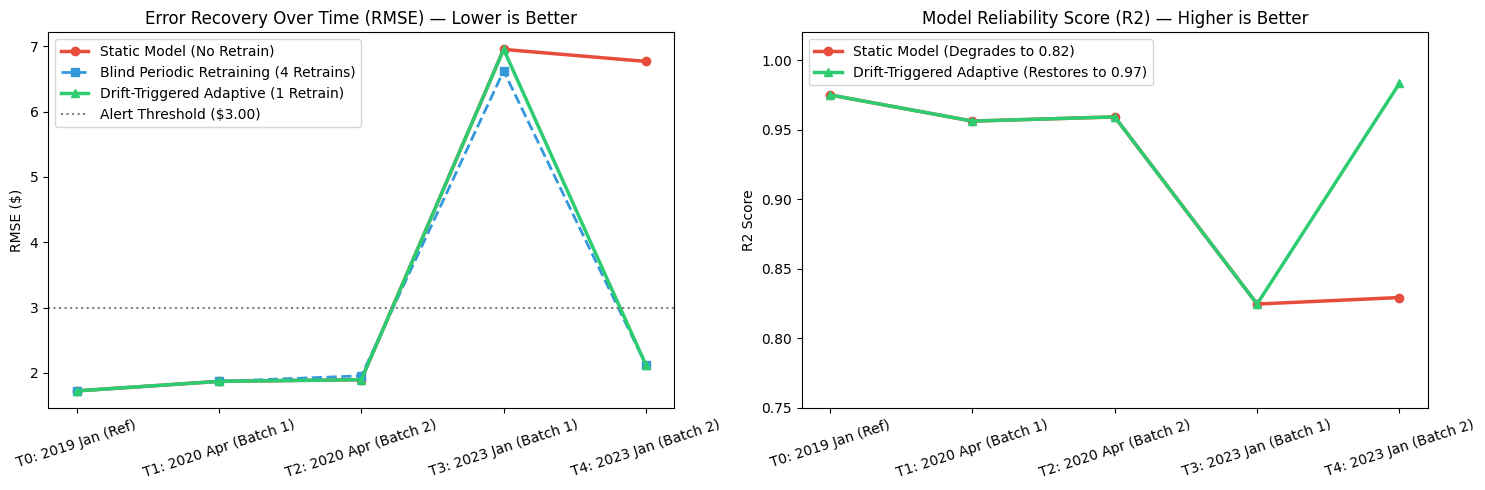

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score

mid_2020 = len(df_2020_ready) // 2
mid_2023 = len(df_2023_ready) // 2

stream_batches = [
    ("T0: 2019 Jan (Ref)", X_test_2019, y_test_2019),
    ("T1: 2020 Apr (Batch 1)", df_2020_ready[feature_cols].iloc[:mid_2020], df_2020_ready[target_col].iloc[:mid_2020]),
    ("T2: 2020 Apr (Batch 2)", df_2020_ready[feature_cols].iloc[mid_2020:], df_2020_ready[target_col].iloc[mid_2020:]),
    ("T3: 2023 Jan (Batch 1)", df_2023_ready[feature_cols].iloc[:mid_2023], df_2023_ready[target_col].iloc[:mid_2023]),
    ("T4: 2023 Jan (Batch 2)", df_2023_ready[feature_cols].iloc[mid_2023:], df_2023_ready[target_col].iloc[mid_2023:])
]

def train_xgb(X, y):
    m = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
    m.fit(X, y)
    return m

static_model = baseline_model
periodic_model = baseline_model
adaptive_model = baseline_model

RMSE_THRESHOLD = 3.0
retrain_logs = []
history = []

for i, (b_name, X_b, y_b) in enumerate(stream_batches):
    # --- Strategy 1: Static Model ---
    pred_static = static_model.predict(X_b)
    rmse_static = np.sqrt(mean_squared_error(y_b, pred_static))
    r2_static = r2_score(y_b, pred_static)

    # --- Strategy 2: Blind Periodic Retraining
    pred_periodic = periodic_model.predict(X_b)
    rmse_periodic = np.sqrt(mean_squared_error(y_b, pred_periodic))
    r2_periodic = r2_score(y_b, pred_periodic)
    if i > 0:
        periodic_model = train_xgb(X_b, y_b)

    # --- Strategy 3: Smart Drift-Triggered Retraining ---
    pred_adaptive = adaptive_model.predict(X_b)
    rmse_adaptive = np.sqrt(mean_squared_error(y_b, pred_adaptive))
    r2_adaptive = r2_score(y_b, pred_adaptive)

    action = "No Retrain Needed (Model Reliable)"
    if i > 0 and rmse_adaptive > RMSE_THRESHOLD:

        adaptive_model = train_xgb(X_b, y_b)
        action = "DRIFT ALERT! Model Retrained & Adapted"
        retrain_logs.append(b_name)

    history.append({
        "Time Window": b_name,
        "Static RMSE ($)": round(rmse_static, 3),
        "Periodic RMSE ($)": round(rmse_periodic, 3),
        "Adaptive RMSE ($)": round(rmse_adaptive, 3),
        "Static R2": round(r2_static, 4),
        "Adaptive R2": round(r2_adaptive, 4),
        "Adaptive System Decision": action
    })

history_df = pd.DataFrame(history)
print("=== FINAL RELIABILITY RESTORATION & RETRAINING REPORT ===")
display(history_df)

# 2. Final Reliability Curve Plot (Main Deliverable Graph)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# RMSE Comparison Line Chart
axes[0].plot(history_df["Time Window"], history_df["Static RMSE ($)"], marker='o', linewidth=2.5, color='#e74c3c', label='Static Model (No Retrain)')
axes[0].plot(history_df["Time Window"], history_df["Periodic RMSE ($)"], marker='s', linestyle='--', linewidth=2, color='#3498db', label='Blind Periodic Retraining (4 Retrains)')
axes[0].plot(history_df["Time Window"], history_df["Adaptive RMSE ($)"], marker='^', linewidth=2.5, color='#2ecc71', label=f'Drift-Triggered Adaptive ({len(retrain_logs)} Retrain)')
axes[0].axhline(RMSE_THRESHOLD, color='gray', linestyle=':', label='Alert Threshold ($3.00)')
axes[0].set_title("Error Recovery Over Time (RMSE) — Lower is Better")
axes[0].set_ylabel("RMSE ($)")
axes[0].tick_params(axis='x', rotation=18)
axes[0].legend()

# R2 Reliability Comparison Line Chart
axes[1].plot(history_df["Time Window"], history_df["Static R2"], marker='o', linewidth=2.5, color='#e74c3c', label='Static Model (Degrades to 0.82)')
axes[1].plot(history_df["Time Window"], history_df["Adaptive R2"], marker='^', linewidth=2.5, color='#2ecc71', label='Drift-Triggered Adaptive (Restores to 0.97)')
axes[1].set_title("Model Reliability Score (R2) — Higher is Better")
axes[1].set_ylabel("R2 Score")
axes[1].set_ylim(0.75, 1.02)
axes[1].tick_params(axis='x', rotation=18)
axes[1].legend()

plt.tight_layout()
plt.show()

Streamlit App Code

In [17]:
!pip install -q streamlit pyngrok
!npm install -g localtunnel

import os
folder_path = "/content/drive/MyDrive/Data_Drift_project"

# Featured DataFrames ko save karein taake Streamlit app unhein load kar sake
df_2019_ready.to_csv(os.path.join(folder_path, "featured_2019.csv"), index=False)
df_2020_ready.to_csv(os.path.join(folder_path, "featured_2020.csv"), index=False)
df_2023_ready.to_csv(os.path.join(folder_path, "featured_2023.csv"), index=False)
print("Streamlit installed & featured CSVs saved!")

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋
added 22 packages in 3s
⠋
⠋3 packages are looking for funding
⠋  run `npm fund` for details
⠋Streamlit installed & featured CSVs saved!


In [18]:
%%writefile /content/drive/MyDrive/Data_Drift_project/app.py
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

st.set_page_config(page_title="ML Model Reliability Under Data Drift", layout="wide")
st.title("🚕 ML Model Reliability & Drift Monitoring System")
st.markdown("Detect **Covariate & Concept Drift** across time and restore model reliability using **Drift-Triggered Adaptive Retraining**.")

def calculate_psi(expected, actual, buckets=10):
    breakpoints = np.unique(np.percentile(expected, np.linspace(0, 100, buckets + 1)))
    expected_counts = np.histogram(expected, bins=breakpoints)[0] / len(expected)
    actual_counts = np.histogram(actual, bins=breakpoints)[0] / len(actual)
    expected_counts = np.where(expected_counts == 0, 0.0001, expected_counts)
    actual_counts = np.where(actual_counts == 0, 0.0001, actual_counts)
    return round(float(np.sum((actual_counts - expected_counts) * np.log(actual_counts / expected_counts))), 4)

def get_drift_status(psi):
    if psi < 0.1:
        return "🟢 Safe (No Drift)"
    elif psi < 0.2:
        return "🟡 Warning (Moderate Drift)"
    else:
        return "🔴 Alert (Severe Drift)"

@st.cache_resource
def train_baseline_model(df_ref, features, target):
    X = df_ref[features]
    y = df_ref[target]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    metrics = {
        "rmse": round(float(np.sqrt(mean_squared_error(y_test, preds))), 3),
        "mae": round(float(mean_absolute_error(y_test, preds)), 3),
        "r2": round(float(r2_score(y_test, preds)), 4)
    }
    return model, metrics

st.sidebar.header("⚙️ Pipeline Configuration")
data_mode = st.sidebar.radio("Data Source:", ["Auto-Load Local Featured CSVs", "Upload Custom CSVs"])
rmse_threshold = st.sidebar.slider("RMSE Drift Alert Threshold ($)", min_value=2.0, max_value=6.0, value=3.0, step=0.2)

feature_cols = [
    'passenger_count', 'trip_distance', 'ratecodeid',
    'pulocationid', 'dolocationid', 'payment_type',
    'trip_duration_min', 'pickup_hour', 'day_of_week', 'is_weekend'
]
target_col = 'fare_amount'

df_ref, df_prod = None, None
batch_name = "Production Batch"

if data_mode == "Auto-Load Local Featured CSVs":
    batch_choice = st.sidebar.selectbox(
        "Select Production Batch to Monitor:",
        ["T1: 2020 Apr (COVID Lockdown)", "T2: 2023 Jan (Post-COVID Inflation)"]
    )
    try:
        df_ref = pd.read_csv("featured_2019.csv")
        if "2020" in batch_choice:
            df_prod = pd.read_csv("featured_2020.csv")
            batch_name = "2020 Apr (Lockdown)"
        else:
            df_prod = pd.read_csv("featured_2023.csv")
            batch_name = "2023 Jan (Inflation)"
    except FileNotFoundError:
        st.error("Local files not found. Switch to 'Upload Custom CSVs' in the sidebar.")
else:
    ref_file = st.sidebar.file_uploader("Upload Reference CSV (2019)", type=["csv"])
    prod_file = st.sidebar.file_uploader("Upload Production Batch CSV", type=["csv"])
    if ref_file and prod_file:
        df_ref = pd.read_csv(ref_file)
        df_prod = pd.read_csv(prod_file)
        batch_name = prod_file.name

if df_ref is not None and df_prod is not None:
    baseline_model, ref_metrics = train_baseline_model(df_ref, feature_cols, target_col)
    prod_preds = baseline_model.predict(df_prod[feature_cols])
    prod_rmse = round(float(np.sqrt(mean_squared_error(df_prod[target_col], prod_preds))), 3)
    prod_r2 = round(float(r2_score(df_prod[target_col], prod_preds)), 4)

    st.subheader(f"📊 Model Reliability Monitor: 2019 Baseline vs. {batch_name}")
    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Baseline RMSE (2019)", f"${ref_metrics['rmse']}")
    col2.metric(f"Production RMSE ({batch_name})", f"${prod_rmse}", delta=f"{round(prod_rmse - ref_metrics['rmse'], 3)}$", delta_color="inverse")
    col3.metric("Baseline R² Score", f"{ref_metrics['r2']}")
    col4.metric(f"Production R² ({batch_name})", f"{prod_r2}", delta=f"{round(prod_r2 - ref_metrics['r2'], 4)}")

    if prod_rmse > rmse_threshold:
        st.error(f"🚨 **CRITICAL RELIABILITY ALERT:** Production RMSE (${prod_rmse}) exceeded threshold (${rmse_threshold}). Retraining required.")
    else:
        st.success(f"✅ **MODEL RELIABLE:** Production RMSE (${prod_rmse}) is within safe threshold (${rmse_threshold}).")

    st.divider()
    st.subheader("🔍 Statistical Drift Audit (PSI & KS-Test)")
    check_cols = ['trip_distance', 'trip_duration_min', 'passenger_count', 'pickup_hour', 'fare_amount']
    drift_rows = []
    for col in check_cols:
        psi_val = calculate_psi(df_ref[col], df_prod[col])
        ks_stat, p_val = ks_2samp(df_ref[col], df_prod[col])
        drift_rows.append({
            "Column": col,
            "Type": "Target (Concept Drift)" if col == "fare_amount" else "Feature (Covariate Drift)",
            "PSI Score": psi_val,
            "Drift Status": get_drift_status(psi_val),
            "KS Statistic": round(float(ks_stat), 4),
            "P-Value": round(float(p_val), 5)
        })
    st.dataframe(pd.DataFrame(drift_rows), use_container_width=True)

    st.subheader("📈 Distribution Shift Comparison (Reference vs. Production)")
    selected_feature = st.selectbox("Select Feature / Target to Visualize:", check_cols, index=4)
    fig, ax = plt.subplots(figsize=(10, 3.5))
    sns.kdeplot(df_ref[selected_feature], ax=ax, label="2019 Reference", fill=True, alpha=0.35, color="#2ecc71", clip=(0, 50))
    sns.kdeplot(df_prod[selected_feature], ax=ax, label=batch_name, fill=True, alpha=0.35, color="#e74c3c", clip=(0, 50))
    ax.set_title(f"Distribution Shift: {selected_feature}")
    ax.legend()
    st.pyplot(fig)

    st.divider()
    st.subheader("🛠️ Drift Mitigation: Adaptive Retraining Simulator")
    if st.button("Trigger Adaptive Retraining on Production Batch"):
        with st.spinner("Retraining XGBoost on production batch..."):
            mid = len(df_prod) // 2
            X_adapt, y_adapt = df_prod[feature_cols].iloc[:mid], df_prod[target_col].iloc[:mid]
            X_eval, y_eval = df_prod[feature_cols].iloc[mid:], df_prod[target_col].iloc[mid:]

            adapted_model = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
            adapted_model.fit(X_adapt, y_adapt)

            new_preds = adapted_model.predict(X_eval)
            new_rmse = round(float(np.sqrt(mean_squared_error(y_eval, new_preds))), 3)
            new_r2 = round(float(r2_score(y_eval, new_preds)), 4)

            c1, c2 = st.columns(2)
            c1.metric("Restored RMSE ($)", f"${new_rmse}", delta=f"{round(new_rmse - prod_rmse, 3)}$", delta_color="inverse")
            c2.metric("Restored R² Score", f"{new_r2}", delta=f"{round(new_r2 - prod_r2, 4)}")
            st.success("🎉 Model successfully adapted to new data distribution and reliability restored!")

Writing /content/drive/MyDrive/Data_Drift_project/app.py


In [19]:
import os
os.chdir("/content/drive/MyDrive/Data_Drift_project")

!wget -q -O - ipv4.icanhazip.com
!streamlit run app.py & npx localtunnel --port 8501

34.29.185.202
⠙⠹⠸⠼⠴⠦⠧

2026-11-20 11:25:26.178 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.29.185.202:8501

  Stopping...
^C


In [20]:
import subprocess, time, os
from google.colab import output

# Working directory set karein taake CSVs auto-load hon
os.chdir("/content/drive/MyDrive/Data_Drift_project")

# Purana streamlit process band karke naya background mein start karein
!pkill -f streamlit || true
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(3)

# Direct Colab browser link generate karein
output.serve_kernel_port_as_window(8501)

^C
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [21]:
import subprocess, time, os
from google.colab import output

os.chdir("/content/drive/MyDrive/Data_Drift_project")

# Purana process band karke Streamlit start karein
!pkill -f streamlit || true
subprocess.Popen([
    "streamlit", "run", "app.py",
    "--server.port", "8501",
    "--server.headless", "true",
    "--server.enableCORS", "false",
    "--server.enableXsrfProtection", "false"
])
time.sleep(3)

# Seedha Colab cell ke andar app kholein
output.serve_kernel_port_as_iframe(8501, height=800)

^C


<IPython.core.display.Javascript object>

In [22]:
!pip install -q gradio

import gradio as gr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ks_2samp
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import os

# 1. Data Load & Baseline Model Train
folder_path = "/content/drive/MyDrive/Data_Drift_project"
df_2019 = pd.read_csv(os.path.join(folder_path, "featured_2019.csv"))
df_2020 = pd.read_csv(os.path.join(folder_path, "featured_2020.csv"))
df_2023 = pd.read_csv(os.path.join(folder_path, "featured_2023.csv"))

feature_cols = [
    'passenger_count', 'trip_distance', 'ratecodeid',
    'pulocationid', 'dolocationid', 'payment_type',
    'trip_duration_min', 'pickup_hour', 'day_of_week', 'is_weekend'
]
target_col = 'fare_amount'

X_train, X_test, y_train, y_test = train_test_split(
    df_2019[feature_cols], df_2019[target_col], test_size=0.2, random_state=42
)
baseline_model = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
baseline_model.fit(X_train, y_train)

base_preds = baseline_model.predict(X_test)
BASE_RMSE = round(float(np.sqrt(mean_squared_error(y_test, base_preds))), 3)
BASE_R2 = round(float(r2_score(y_test, base_preds)), 4)

# 2. PSI Function
def calculate_psi(expected, actual, buckets=10):
    breakpoints = np.unique(np.percentile(expected, np.linspace(0, 100, buckets + 1)))
    e_counts = np.where(np.histogram(expected, bins=breakpoints)[0] / len(expected) == 0, 0.0001, np.histogram(expected, bins=breakpoints)[0] / len(expected))
    a_counts = np.where(np.histogram(actual, bins=breakpoints)[0] / len(actual) == 0, 0.0001, np.histogram(actual, bins=breakpoints)[0] / len(actual))
    return round(float(np.sum((a_counts - e_counts) * np.log(a_counts / e_counts))), 4)

# 3. Main Dashboard Analysis Function
def run_drift_pipeline(batch_choice, rmse_threshold, trigger_retrain):
    df_prod = df_2020 if "2020" in batch_choice else df_2023

    # Static Model Evaluation
    preds = baseline_model.predict(df_prod[feature_cols])
    prod_rmse = round(float(np.sqrt(mean_squared_error(df_prod[target_col], preds))), 3)
    prod_r2 = round(float(r2_score(df_prod[target_col], preds)), 4)

    # Alert Status
    if prod_rmse > rmse_threshold:
        status_msg = f"🚨 DRIFT ALERT! Static RMSE jumped from ${BASE_RMSE} to ${prod_rmse} (R² dropped from {BASE_R2} to {prod_r2})."
    else:
        status_msg = f"✅ MODEL RELIABLE: Static RMSE is ${prod_rmse} (R² = {prod_r2}), safely below ${rmse_threshold} threshold."

    # Adaptive Retraining Logic
    if trigger_retrain:
        mid = len(df_prod) // 2
        adapted = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1)
        adapted.fit(df_prod[feature_cols].iloc[:mid], df_prod[target_col].iloc[:mid])
        new_preds = adapted.predict(df_prod[feature_cols].iloc[mid:])
        new_rmse = round(float(np.sqrt(mean_squared_error(df_prod[target_col].iloc[mid:], new_preds))), 3)
        new_r2 = round(float(r2_score(df_prod[target_col].iloc[mid:], new_preds)), 4)
        status_msg += f"\n\n🛠️ ADAPTIVE RETRAINING APPLIED: Error restored from ${prod_rmse} → ${new_rmse} | R² restored from {prod_r2} → {new_r2}!"

    # PSI & KS-Test Table
    check_cols = ['trip_distance', 'trip_duration_min', 'passenger_count', 'pickup_hour', 'fare_amount']
    rows = []
    for col in check_cols:
        psi = calculate_psi(df_2019[col], df_prod[col])
        ks, pval = ks_2samp(df_2019[col], df_prod[col])
        alert = "🔴 Severe Drift" if psi >= 0.2 else ("🟡 Moderate" if psi >= 0.1 else "🟢 Safe")
        rows.append([col, psi, alert, round(float(ks), 4), round(float(pval), 5)])
    drift_table = pd.DataFrame(rows, columns=["Feature / Target", "PSI Score", "Status", "KS Stat", "P-Value"])

    # KDE Plot
    fig, ax = plt.subplots(figsize=(8, 3.5))
    sns.kdeplot(df_2019['fare_amount'], ax=ax, label="2019 Reference", fill=True, alpha=0.35, color="#2ecc71", clip=(0, 50))
    sns.kdeplot(df_prod['fare_amount'], ax=ax, label=batch_choice, fill=True, alpha=0.35, color="#e74c3c", clip=(0, 50))
    ax.set_title("Target Distribution Shift: Fare Amount ($)")
    ax.legend()
    plt.tight_layout()

    return status_msg, drift_table, fig

# 4. Launch Gradio Web App with Public Link
demo = gr.Interface(
    fn=run_drift_pipeline,
    inputs=[
        gr.Dropdown(["T1: 2020 Apr (COVID Lockdown)", "T2: 2023 Jan (Post-COVID Inflation)"], value="T2: 2023 Jan (Post-COVID Inflation)", label="Select Production Batch"),
        gr.Slider(2.0, 6.0, value=3.0, step=0.2, label="RMSE Drift Alert Threshold ($)"),
        gr.Checkbox(value=True, label="Trigger Drift-Adaptive Retraining")
    ],
    outputs=[
        gr.Textbox(label="System Health & Reliability Alert", lines=4),
        gr.Dataframe(label="Statistical Drift Report (PSI & KS-Test)"),
        gr.Plot(label="Distribution Shift Visualization")
    ],
    title="🚕 ML Model Reliability Under Data Drift",
    description="Interactive Drift Monitoring & Self-Healing ML Pipeline (Baseline 2019 vs 2020 & 2023)"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f577abadc6901cf812.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
